# Pole-Mounted Transformers – Imputation Method Experiment

**Jira PGS219-105 · Sprint 2 · Team 19 (PG-S2-19), SA Power Networks capstone**

## 1. Executive summary

Five imputation methods compared on recovering a missing **categorical nameplate
attribute**, using 933 oil-test records from 105 real power transformers (public
Mendeley data).

**The experiment design matters more than the method.** The same baseline scores
**0.95 when individual rows are masked and 0.33 when whole transformers are** — a
62-point gap, because repeated samples of one unit leak the answer. Under the
leak-free design the best method reaches **0.77 against a 0.65 baseline**, or
**0.94** once a synthetic catch-all class is dropped. Two nameplate features beat
all sixteen, and on the one field with no signal the most sophisticated method
scored below a plain median fill.

**Scope.** Public data on **substation** transformers — not SAPN data, not
pole-mounted assets. `transformer_type` does not exist here, so primary voltage
class (`Tp`) stands in for it. **The findings are meant to transfer; the accuracy
figures are not.**

## 2. Data

**Primary** — `data/synthetic/transformers/power_transformers_oil.csv`, from the Mendeley study
[*Dissolved gas and oil quality data of power transformers*](https://data.mendeley.com/datasets/98f4z3f8tx/2).
**933 rows × 47 columns; 105 transformers, 1–22 oil samples each.** One row is one
oil sample from one transformer at one point in time.

| Field group | Columns | Behaviour |
|---|---|---|
| Unit identifier | `Transformer` | groups the repeated samples |
| Nameplate | `Power (MVA)`, `Tp`, `Ts`, `Year`, `Impedance (kV)`, `Temperature Rise` | **constant per transformer** |
| Dissolved gases | `Hydrogen`, `Methane`, `Ethane`, `Ethylene`, `Acetylene`, `Carbon Monoxide`, `Carbon Dioxide`, `Nitrogen`, `Oxygen`, `TDCG (ppm)` | vary per sample |
| Oil quality | `Moisture Content (ppm)`, `Neutralization Number (mg KOH/g)`, `Interfacial Tension (dynes/cm)`, `Power Factor at 25 °C`, `Color`, … | vary per sample |
| Legacy diagnoses | `Diagnosis by Duval`, `… by Rogers`, `… by Dornenburg`, `… by Basic Gas Ratio` | **derived from the gases — never a valid target** |

**Not SAPN data.** Substation transformers rated in MVA at 69–230 kV, not
pole-mounted distribution units. No `transformer_type`, no feeder, no location.
Provenance and licence: the module docstring of
`src/team19_asset_data/transformers/load_oil_data.py` and the Mendeley page above.

**Secondary** — `data/synthetic/transformers/transformer_health_index.csv`, 470 rows with no
missing values, used in section 11 as a numeric cross-check.

## 3. Environment

Conda environment **`pgs219`**, Python 3.12.14.

```bash
conda create -y -n pgs219 python=3.12
conda activate pgs219
conda install -y -c conda-forge llvm-openmp   # macOS only: lightgbm needs libomp
pip install -r requirements.txt
pip install -e .
```

Two constraints are load-bearing:

- **`lightgbm` pinned to 4.5.0.** miceforest 6.0.5 uses a private LightGBM API
  that changed in 4.6; a newer version breaks `kernel.mice()`.
- **macOS needs `libomp`.** Without it `import miceforest` fails. pip cannot
  supply it — use conda or Homebrew.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import miceforest as mf
import numpy as np
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.experimental import enable_iterative_imputer  # noqa: F401
from sklearn.impute import IterativeImputer, KNNImputer
from sklearn.metrics import accuracy_score, confusion_matrix, mean_absolute_error, r2_score
from sklearn.preprocessing import StandardScaler

from team19_asset_data.transformers.load_oil_data import load_clean_dataset

REPO_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
pd.set_option("display.width", 200)

## 4. Load and clean

All cleaning lives in `src/team19_asset_data/transformers/load_oil_data.py`; its
docstring records every rule. Nothing is cleaned in this notebook. The raw Mendeley
download is not committed, so the notebook reads the already-cleaned CSV from
`data/synthetic/transformers/` via `load_clean_dataset`.

In [2]:
raw = load_clean_dataset(REPO_ROOT)
print(f"{len(raw)} rows, {raw['Transformer'].nunique()} transformers, {raw.shape[1]} columns")
print(f"samples per transformer: min={raw.groupby('Transformer').size().min()}, "
      f"median={raw.groupby('Transformer').size().median():.0f}, "
      f"max={raw.groupby('Transformer').size().max()}")

# TARGET CHOICE: the register field named as missing is `transformer_type`, which
# does not exist here. `Tp` (primary voltage, kV) is the closest legitimate
# stand-in - a discrete nameplate attribute that real asset registers lose.
# Voltage levels appearing in fewer than MIN_CLASS_ROWS rows are folded into
# "other"; section 10 shows what that costs.
UNIT, TARGET = "Transformer", "tp_class"
MASK_RATE, N_SEEDS, MIN_CLASS_ROWS = 0.2, 10, 20

levels = raw["Tp"].value_counts()
df = raw[raw["Tp"].notna()].copy()
df[TARGET] = np.where(df["Tp"].isin(levels[levels >= MIN_CLASS_ROWS].index),
                      df["Tp"].astype(str), "other")
df = df.reset_index(drop=True)
CLASSES = sorted(df[TARGET].unique())

NAMEPLATE = ["Power (MVA)", "Year"]
GASES = ["Hydrogen", "Methane", "Ethane", "Ethylene", "Acetylene",
         "Carbon Monoxide", "Carbon Dioxide", "Nitrogen", "Oxygen", "TDCG (ppm)"]
OIL = ["Moisture Content (ppm)", "Neutralization Number (mg KOH/g)",
       "Interfacial Tension (dynes/cm)", "Power Factor at 25 °C"]
FEATURES = NAMEPLATE + GASES + OIL

print(f"\nrows with a known Tp: {len(df)} of {len(raw)}; transformers: {df[UNIT].nunique()} of {raw['Transformer'].nunique()}")
print(f"\ntarget `{TARGET}` - rows per class:\n{df[TARGET].value_counts().to_string()}")
print(f"\ntransformers per class:\n{df.groupby(UNIT)[TARGET].first().value_counts().to_string()}")
print(f"\n{len(FEATURES)} predictors; `Ts` deliberately excluded (sibling nameplate field)")

933 rows, 105 transformers, 47 columns
samples per transformer: min=1, median=7, max=22

rows with a known Tp: 931 of 933; transformers: 104 of 105

target `tp_class` - rows per class:
tp_class
69.0     423
230.0    255
other    128
138.0    125

transformers per class:
tp_class
230.0    39
69.0     32
other    18
138.0    15

16 predictors; `Ts` deliberately excluded (sibling nameplate field)


## 5. Experiment design

**Target** — `Tp`, primary voltage in kV, folded to four classes: 69 / 138 / 230
and `other`.

**Masking — whole transformers, not rows.** Nameplate attributes are constant
within a transformer and each unit contributes up to 22 samples, so masking rows
at random leaves the answer sitting in a sibling row. The cell below measures it:
one target, one baseline, only the masking scheme changes.

**Evaluation — per transformer.** Held-out units contribute unequal numbers of
rows, so row-level scoring over-weights heavily sampled units. Predictions are
pooled by majority vote within each unit. This also matches the business
question: the voltage class of the *transformer*, not of each oil sample.

**Repetition** — every configuration runs over 10 seeds, reported as mean ± std.

In [3]:
def grouped_mask(frame, seed, rate=MASK_RATE):
    """Hold out every row of a random subset of transformers."""
    rng = np.random.default_rng(seed)
    units = frame[UNIT].unique()
    held = rng.choice(units, size=int(len(units) * rate), replace=False)
    return frame[UNIT].isin(held)


def per_unit_accuracy(y_true, y_pred, units):
    """Majority-vote each transformer's rows, then score once per transformer."""
    vote = (pd.DataFrame({"u": units, "t": y_true, "p": y_pred})
              .groupby("u").agg(t=("t", "first"), p=("p", lambda s: s.mode().iat[0])))
    return accuracy_score(vote.t, vote.p)


def row_mask(frame, seed, rate=MASK_RATE):
    """Mask individual rows at random - the design this notebook argues against."""
    rng = np.random.default_rng(seed)
    picked = rng.choice(frame.index.to_numpy(), size=int(len(frame) * rate), replace=False)
    return pd.Series(frame.index.isin(picked), index=frame.index)


def mode_within_unit(frame, mask, seed):
    """Baseline: most common class among the same transformer's unmasked rows.

    Under grouped masking no such rows exist, so it falls back to the global mode.
    """
    obs = frame[~mask]
    by_unit = obs.groupby(UNIT)[TARGET].agg(lambda s: s.mode().iat[0])
    return frame.loc[mask, UNIT].map(by_unit).fillna(obs[TARGET].mode().iat[0]).to_numpy()


comparison = []
for seed in range(N_SEEDS):
    for label, mask in [("rows at random", row_mask(df, seed)),
                        ("whole transformers", grouped_mask(df, seed))]:
        comparison.append({
            "masking": label,
            "accuracy": per_unit_accuracy(df.loc[mask, TARGET].to_numpy(),
                                          mode_within_unit(df, mask, seed),
                                          df.loc[mask, UNIT].to_numpy())})
print("Same target, same baseline - only the masking scheme differs:\n")
print(pd.DataFrame(comparison).groupby("masking")["accuracy"]
        .agg(["mean", "std"]).round(3).to_string(), "\n")

leak = np.mean([df.loc[m, UNIT].isin(df.loc[~m, UNIT]).mean()
                for m in (row_mask(df, s) for s in range(N_SEEDS))])
print(f"under row masking, {leak:.1%} of masked rows still have an unmasked sibling row")
print(f"`{TARGET}` is constant within {(df.groupby(UNIT)[TARGET].nunique() == 1).mean():.1%} of transformers")

Same target, same baseline - only the masking scheme differs:

                     mean    std
masking                         
rows at random      0.953  0.024
whole transformers  0.330  0.059 

under row masking, 98.9% of masked rows still have an unmasked sibling row
`tp_class` is constant within 95.2% of transformers


## 6. Methods

Five methods, all scored on identical masks.

| Method | Treats the target as | Note |
|---|---|---|
| Baseline — grouped mode | categorical | most common class among training units of similar `Power (MVA)` |
| KNN Imputer | categorical via one-hot | one indicator column per class, imputed then `argmax` |
| IterativeImputer | **numeric** | `BayesianRidge` regression — **continuous fields only; it degenerates here** |
| miceforest | categorical (native) | LightGBM multiclass on a `category` dtype |
| RandomForestClassifier | categorical (native) | direct supervised fit on observed rows |

`IterativeImputer` is included deliberately: it is the default many people reach
for, and section 8 shows it collapsing to the majority class. That failure is
worth recording.

In [4]:
def _scaled(frame, feats):
    return pd.DataFrame(StandardScaler().fit_transform(frame[feats]),
                        columns=feats, index=frame.index)


def baseline_grouped_mode(frame, mask, seed):
    band = pd.qcut(frame["Power (MVA)"], 4, labels=False, duplicates="drop")
    by_band = frame[~mask].groupby(band[~mask])[TARGET].agg(lambda s: s.mode().iat[0])
    return band[mask].map(by_band).fillna(frame.loc[~mask, TARGET].mode().iat[0]).to_numpy()


def knn_onehot(frame, mask, seed, k=5):
    Z = _scaled(frame, FEATURES)
    for c in CLASSES:
        Z[f"__{c}"] = (frame[TARGET] == c).astype(float).mask(mask)
    out = pd.DataFrame(KNNImputer(n_neighbors=k).fit_transform(Z), columns=Z.columns, index=frame.index)
    return np.array(CLASSES)[out.loc[mask, [f"__{c}" for c in CLASSES]].to_numpy().argmax(axis=1)]


def iterative_ordinal(frame, mask, seed, order=None):
    order = order or CLASSES
    Z = _scaled(frame, FEATURES)
    Z[TARGET] = frame[TARGET].map({c: i for i, c in enumerate(order)}).mask(mask)
    out = pd.DataFrame(IterativeImputer(random_state=0).fit_transform(Z), columns=Z.columns, index=frame.index)
    return np.array(order)[np.clip(out.loc[mask, TARGET].round(), 0, len(order) - 1).astype(int)]


def miceforest_native(frame, mask, seed, iterations=3):
    d = frame[[TARGET] + FEATURES].copy()
    d.loc[mask, TARGET] = np.nan
    d[TARGET] = d[TARGET].astype("category")
    kernel = mf.ImputationKernel(d, num_datasets=1, random_state=seed)
    kernel.mice(iterations)
    return kernel.complete_data(dataset=0).loc[mask, TARGET].to_numpy()


def random_forest(frame, mask, seed, feats=None):
    feats = feats or FEATURES
    X = np.log1p(frame[feats].clip(lower=0))
    X = X.fillna(X[~mask].median())
    weight = 1 / frame[UNIT].map(frame.groupby(UNIT).size())   # each unit counts once
    model = RandomForestClassifier(n_estimators=400, random_state=seed, n_jobs=-1)
    model.fit(X[~mask], frame.loc[~mask, TARGET], sample_weight=weight[~mask])
    return model.predict(X[mask])


METHODS = {
    "Baseline (grouped mode by MVA)": baseline_grouped_mode,
    "KNN Imputer (one-hot, k=5)": knn_onehot,
    "IterativeImputer (continuous only)": iterative_ordinal,
    "miceforest (native categorical)": miceforest_native,
    "RandomForestClassifier": random_forest,
}


def evaluate(frame, methods, seeds=N_SEEDS):
    """Run every method over `seeds` grouped masks; return per-seed scores."""
    out = []
    for seed in range(seeds):
        mask = grouped_mask(frame, seed)
        y = frame.loc[mask, TARGET].to_numpy()
        units = frame.loc[mask, UNIT].to_numpy()
        for name, fn in methods.items():
            out.append({"seed": seed, "method": name,
                        "accuracy": per_unit_accuracy(y, fn(frame, mask, seed), units)})
    return pd.DataFrame(out)


def summarise(scores, order):
    s = scores.groupby("method")["accuracy"].agg(["mean", "std"]).reindex(order)
    return s.rename(columns={"mean": "per-unit accuracy", "std": "± std"}).round(3)

## 7. Main experiment

Five methods, 10 grouped masks each, scored per transformer.

In [5]:
scores = evaluate(df, METHODS)
main_table = summarise(scores, list(METHODS))
n_units = df[UNIT].nunique()
print(f"Tp voltage class - {len(CLASSES)} classes, "
      f"{int(n_units * MASK_RATE)} of {n_units} transformers held out, {N_SEEDS} seeds\n")
print(main_table.to_string())

Tp voltage class - 4 classes, 20 of 104 transformers held out, 10 seeds

                                    per-unit accuracy  ± std
method                                                      
Baseline (grouped mode by MVA)                  0.645  0.117
KNN Imputer (one-hot, k=5)                      0.715  0.123
IterativeImputer (continuous only)              0.615  0.094
miceforest (native categorical)                 0.755  0.104
RandomForestClassifier                          0.770  0.109


The `other` class is an artefact: nine scattered values (13.2, 34.5, 66, 143,
145 kV …, plus 19 rows recorded as 0 kV) pooled into one label with nothing in
common. Repeating the experiment
on the three genuine voltage classes only:

In [6]:
df3 = df[df[TARGET] != "other"].reset_index(drop=True)
scores3 = evaluate(df3, {"RandomForestClassifier": random_forest})

kv = ' / '.join(sorted(df3[TARGET].unique(), key=float))
print(f"3 classes ({kv} kV), `other` removed\n")
print(summarise(scores3, ["RandomForestClassifier"]).to_string())

3 classes (69.0 / 138.0 / 230.0 kV), `other` removed

                        per-unit accuracy  ± std
method                                          
RandomForestClassifier              0.935   0.07


## 8. Encoding comparison

Numeric imputers need the categorical target encoded. Three encodings are
compared, holding everything else fixed:

- **ordinal, alphabetical** — `sorted()` on the string labels gives
  `138.0 < 230.0 < 69.0 < other`, which is not the voltage order;
- **ordinal, true kV order** — `69 < 138 < 230 < other`;
- **one-hot + argmax** — one indicator column per class, no order assumed.

In [7]:
ALPHA = sorted(df[TARGET].unique())            # '138.0', '230.0', '69.0', 'other'
KV_ORDER = ["69.0", "138.0", "230.0", "other"]  # true voltage order


def ordinal_impute(frame, mask, seed, kind, order):
    """Encode the target as an ordinal code, impute numerically, round back."""
    Z = _scaled(frame, FEATURES)
    Z[TARGET] = frame[TARGET].map({c: i for i, c in enumerate(order)}).mask(mask)
    imp = KNNImputer(n_neighbors=5) if kind == "knn" else IterativeImputer(random_state=0)
    out = pd.DataFrame(imp.fit_transform(Z), columns=Z.columns, index=frame.index)
    return np.array(order)[np.clip(out.loc[mask, TARGET].round(), 0, len(order) - 1).astype(int)]


def onehot_impute(frame, mask, seed, kind):
    """One indicator column per class; impute, then take the argmax."""
    Z = _scaled(frame, FEATURES)
    for c in CLASSES:
        Z[f"__{c}"] = (frame[TARGET] == c).astype(float).mask(mask)
    imp = KNNImputer(n_neighbors=5) if kind == "knn" else IterativeImputer(random_state=0)
    out = pd.DataFrame(imp.fit_transform(Z), columns=Z.columns, index=frame.index)
    return np.array(CLASSES)[out.loc[mask, [f"__{c}" for c in CLASSES]].to_numpy().argmax(axis=1)]


encodings = {
    "KNN  · ordinal (alphabetical)":   lambda f, m, s: ordinal_impute(f, m, s, "knn", ALPHA),
    "KNN  · ordinal (true kV order)":  lambda f, m, s: ordinal_impute(f, m, s, "knn", KV_ORDER),
    "KNN  · one-hot + argmax":         lambda f, m, s: onehot_impute(f, m, s, "knn"),
    "MICE · ordinal (alphabetical)":   lambda f, m, s: ordinal_impute(f, m, s, "mice", ALPHA),
    "MICE · ordinal (true kV order)":  lambda f, m, s: ordinal_impute(f, m, s, "mice", KV_ORDER),
    "MICE · one-hot + argmax":         lambda f, m, s: onehot_impute(f, m, s, "mice"),
    "miceforest (native categorical)": miceforest_native,
    "RandomForestClassifier":          random_forest,
}

enc_table = summarise(evaluate(df, encodings), list(encodings))
print(enc_table.to_string())

                                 per-unit accuracy  ± std
method                                                   
KNN  · ordinal (alphabetical)                0.670  0.095
KNN  · ordinal (true kV order)               0.590  0.129
KNN  · one-hot + argmax                      0.715  0.123
MICE · ordinal (alphabetical)                0.615  0.094
MICE · ordinal (true kV order)               0.480  0.121
MICE · one-hot + argmax                      0.330  0.059
miceforest (native categorical)              0.755  0.104
RandomForestClassifier                       0.770  0.109


Three things to take from this table.

**One-hot is the right encoding for KNN** — about five points over ordinal
coding, because it assumes no order between classes.

**Correcting the ordinal order makes it worse.** `other` is unordered by
construction, so placing it above 230 kV asserts that a bucket of mostly *low*
voltages is the highest class. The lesson is not "fix the order" but "don't
ordinal-encode an unordered target".

**`IterativeImputer` collapses to the majority class.** Its `BayesianRidge`
estimator regresses each indicator toward the class prior, so `argmax` returns
the largest class — 0.33, below even the baseline. It is a regressor; use it only
on continuous fields.

Encoding repairs help, but never change the ranking: a categorical target belongs
to a classifier.

## 9. Feature ablation

Which columns actually carry the signal? Same masks, same model
(`RandomForestClassifier`), four feature sets.

In [8]:
FEATURE_SETS = {
    "Power (MVA) only":            ["Power (MVA)"],
    "Nameplate only (MVA + Year)": NAMEPLATE,
    "Oil chemistry only":          GASES + OIL,
    "Everything (16 features)":    FEATURES,
}
ablation = summarise(
    evaluate(df, {name: (lambda f, m, s, ft=ft: random_forest(f, m, s, ft))
                  for name, ft in FEATURE_SETS.items()}),
    list(FEATURE_SETS))
ablation.insert(0, "n features", [len(v) for v in FEATURE_SETS.values()])
print(ablation.to_string())

                             n features  per-unit accuracy  ± std
method                                                           
Power (MVA) only                      1              0.770  0.092
Nameplate only (MVA + Year)           2              0.795  0.104
Oil chemistry only                   14              0.600  0.143
Everything (16 features)             16              0.770  0.109


**Two nameplate features beat all sixteen**, and adding the fourteen oil-test
columns *lowers* accuracy.

This is physically coherent. Capacity and voltage class are specified together —
a 50 MVA unit is not a 13.8 kV unit. Oil chemistry records how a transformer has
been *operated*, not what it was *built as*. On its own it lands below the
baseline: some signal, but not enough to beat reading the class off the capacity
rating.

## 10. Confusion matrix

Where does the remaining error sit?

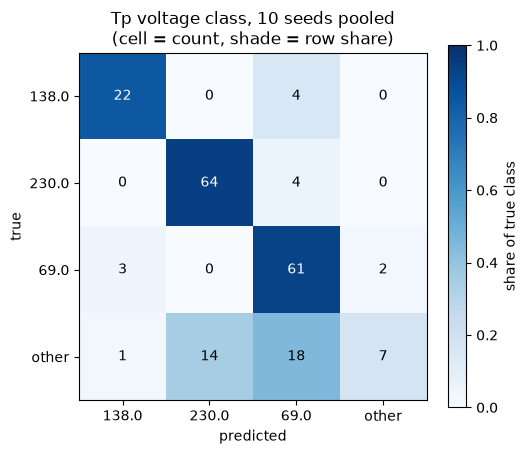

        n  correct  recall
138.0  26       22   0.846
230.0  68       64   0.941
69.0   66       61   0.924
other  40        7   0.175


In [9]:
cm = np.zeros((len(CLASSES), len(CLASSES)), dtype=int)
for seed in range(N_SEEDS):
    mask = grouped_mask(df, seed)
    y, units = df.loc[mask, TARGET].to_numpy(), df.loc[mask, UNIT].to_numpy()
    vote = (pd.DataFrame({"u": units, "t": y, "p": random_forest(df, mask, seed)})
              .groupby("u").agg(t=("t", "first"), p=("p", lambda s: s.mode().iat[0])))
    cm += confusion_matrix(vote.t, vote.p, labels=CLASSES)

fig, ax = plt.subplots(figsize=(5.4, 4.6))
im = ax.imshow(cm / cm.sum(axis=1, keepdims=True), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(CLASSES)), CLASSES); ax.set_yticks(range(len(CLASSES)), CLASSES)
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"Tp voltage class, {N_SEEDS} seeds pooled\n(cell = count, shade = row share)")
for i in range(len(CLASSES)):
    for j in range(len(CLASSES)):
        share = cm[i, j] / cm[i].sum()
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if share > 0.5 else "black")
fig.colorbar(im, ax=ax, label="share of true class"); fig.tight_layout(); plt.show()

recall = pd.DataFrame({"n": cm.sum(axis=1), "correct": np.diag(cm)}, index=CLASSES)
recall["recall"] = (recall.correct / recall.n).round(3)
print(recall.to_string())

The three genuine voltage classes are recovered well. Almost all remaining error
is the synthetic `other` bucket, scattered across the real classes — as it must
be, since it is eight unrelated voltages sharing a label. It is 18 of the 104
units and costs about 16 points of headline accuracy (0.77 → 0.94).

Quoting the three-class figure alone would flatter the result by dropping the
hardest cases. Keeping all four is more useful to an asset owner: **mainstream
voltage classes are recoverable; non-standard ones are not.**

## 11. Numeric cross-check

Does this hold for continuous fields on a different dataset? The secondary
dataset has no missing values, so every cell has ground truth and the mask rate
can be swept cleanly. Rows are independent assessments, so masking is at row
level here.

`Health index` is excluded from the predictors — it is computed from the other
fourteen columns and would leak the masked value back in.

In [10]:
health = pd.read_csv(REPO_ROOT / "data/synthetic/transformers/transformer_health_index.csv")
H_FEATURES = [c for c in health.columns if c != "Health index"]
H_TARGETS = ["Interfacial V", "Water content", "Dielectric rigidity"]
RATES, H_SEEDS = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6], 5


def h_impute(frame, target, how, seed):
    if how == "median":
        return np.full(len(frame), frame[target].median())
    if how == "miceforest":
        kernel = mf.ImputationKernel(frame[H_FEATURES], num_datasets=1, random_state=seed)
        kernel.mice(3)
        return kernel.complete_data(dataset=0)[target].to_numpy()
    scaler = StandardScaler()
    Z = pd.DataFrame(scaler.fit_transform(frame[H_FEATURES]), columns=H_FEATURES)
    out = KNNImputer(n_neighbors=5).fit_transform(Z)
    return pd.DataFrame(scaler.inverse_transform(out), columns=H_FEATURES)[target].to_numpy()


rows = []
for target in H_TARGETS:
    for rate in RATES:
        for seed in range(H_SEEDS):
            rng = np.random.default_rng(seed)
            idx = rng.choice(health.index.to_numpy(), size=int(len(health) * rate), replace=False)
            truth = health.loc[idx, target].to_numpy()
            masked = health.copy(); masked.loc[idx, target] = np.nan
            for how in ["median", "knn", "miceforest"]:
                pred = h_impute(masked, target, how, seed)[idx]
                rows.append({"target": target, "rate": rate, "method": how,
                             "R2": r2_score(truth, pred),
                             "MAE": mean_absolute_error(truth, pred)})
sweep = pd.DataFrame(rows)

print("mean R2 by mask rate (5 seeds)\n")
for target in H_TARGETS:
    piv = sweep[sweep.target == target].groupby(["method", "rate"])["R2"].mean().unstack().round(3)
    print(f"--- {target}"); print(piv.to_string(), "\n")

out_dir = REPO_ROOT / "outputs/PGS219-105"; out_dir.mkdir(parents=True, exist_ok=True)
sweep.to_csv(out_dir / "health_index_mask_sweep.csv", index=False)
print(f"raw results -> {out_dir / 'health_index_mask_sweep.csv'}")

mean R2 by mask rate (5 seeds)

--- Interfacial V
rate          0.1    0.2    0.3    0.4    0.5    0.6
method                                              
knn         0.493  0.447  0.413  0.501  0.429  0.440
median     -0.063 -0.090 -0.081 -0.083 -0.037 -0.069
miceforest  0.353  0.531  0.444  0.423  0.460  0.459 

--- Water content
rate          0.1    0.2    0.3    0.4    0.5    0.6
method                                              
knn         0.311  0.088  0.174  0.116  0.184  0.123
median     -0.093 -0.087 -0.128 -0.082 -0.083 -0.097
miceforest  0.344  0.198  0.232  0.138  0.210  0.186 

--- Dielectric rigidity
rate          0.1    0.2    0.3    0.4    0.5    0.6
method                                              
knn        -0.199  0.030 -0.106 -0.007 -0.035 -0.063
median     -0.025 -0.012 -0.018 -0.014 -0.005 -0.023
miceforest -0.330 -0.191 -0.460 -0.205 -0.189 -0.326 

raw results -> /Users/morgan/Desktop/Capstone Project/Sprint 2/team19-asset-data/outputs/PGS219-105/health_

**Recoverability is a property of the field, not the method.** `Interfacial V`
reaches R² ≈ 0.35–0.53, `Water content` ≈ 0.1–0.35, `Dielectric rigidity` ≤ 0 — the
same ordering at every mask rate.

**The mask rate barely matters.** No decay trend from 10% to 60% missing. The
signal lives in the relationships *between* columns, and 40% of 470 rows still
carries them. A field should not be written off for being mostly empty.

**On the field with no signal, miceforest fell below the median baseline** at
every mask rate — it fits noise where there is nothing to fit.

## 12. Method verdicts

Based on the main experiment, the encoding comparison and the numeric cross-check:

| Method | Verdict | Basis |
|---|---|---|
| Grouped mode baseline | Suitable as reference baseline | Stable, interpretable, low ceiling |
| KNN Imputer (one-hot) | Weak | Below native classifiers on this task |
| IterativeImputer (BayesianRidge) | Unsuitable for categorical targets | Collapses to majority class; continuous fields only |
| miceforest | Suitable | 0.755 ± 0.10, native categorical handling |
| RandomForest Classifier | Suitable | Best overall on this task |

These verdicts are specific to a categorical nameplate target with a small class set. Different fields may reorder methods; a per-field recoverability check remains necessary.

## 13. Key findings

**1. The masking design decides whether a result is real.** The same baseline
scores 0.95 under row masking and 0.33 under transformer masking — 62 points from
experiment design alone. No accuracy figure is interpretable without its masking
scheme stated alongside it.

**2. A single seed is not a result.** An early single-seed run put miceforest at
0.83; its 10-seed mean is 0.755 ± 0.104. With 20 held-out units, one unit is five
points.

**3. Ask which field is recoverable, not whether imputation works.** Identical
methods produce R² from 0.53 down to −0.19 (miceforest, 20% masking) depending
only on the target.

**4. A complex method can do worse than a simple fill.** On `Dielectric
rigidity` — the one field here with no recoverable signal — miceforest scored
−0.19 against a median baseline of −0.01 at 20% masking, and worse at every
other rate. That is one field in one dataset, but
enough reason to check a field before trusting a model on it.

**5. More features is not better.** Two nameplate columns beat all sixteen.
Oil-test columns describe how a unit has been *operated*, not what it was *built
as*.

**6. A synthetic catch-all class depresses everything.** Folding nine unrelated
values into `other` costs about 16 points of headline accuracy.

**7. Categorical targets need classifiers.** One-hot lifts KNN by about five
points and is the correct encoding, but no encoding repair changes the ranking.

**Practical rule.** Before imputing a field in bulk, hide some known values,
recover them, and compare against a mode/median baseline. Clearly above it — use
a model. Near it — fill with mode or median, and be cautious about reaching for
anything more complex.

## 14. Limitations and next steps

**The data does not match the target scenario.** Public Mendeley oil-analysis
data for substation transformers — not SAPN data, not pole-mounted assets, with
no `transformer_type`, feeder or location field. What is validated here is the
*method*, not the result.

**Voltage class is a methodological carrier.** `Tp` stands in for
`transformer_type` because both are discrete nameplate attributes that registers
lose. The comparisons and findings are meant to transfer; **the accuracy figures
are not.**

**Missingness is drawn at random.** Two masking schemes were compared — single
rows and whole transformers — but in both, *which* rows or units get hidden is
drawn uniformly at random (MCAR). Real registers lose fields systematically:
older assets and migrated records lose more. Missingness that depends on observed
values (MAR) or on the hidden value itself (MNAR) is left for Sprint 3. It
matters because systematic missingness can skew an imputed *distribution* even
when per-record accuracy looks fine — and the distribution is what feeds a PoF or
Weibull fit.

**No hyperparameter tuning.** All defaults. Tuning needs a separate tuning mask;
tuning on the evaluation masks would leak.

**Other Sprint 3 gaps.** Downstream impact on a Weibull or PoF fit is not
measured; no distribution-level metrics alongside per-record accuracy; and `Ts`
is excluded as a predictor, though an earlier run showed it worth about four
points — whether using it is legitimate depends on whether SAPN's register loses
`Tp` and `Ts` together.